In [1]:
import numpy as np
import math as math

In [2]:
m = [0.,0.]
angle = 45*math.pi/180
rot = np.array([[math.cos(angle), -math.sin(angle)], [math.sin(angle),
math.cos(angle)]])
lamb = np.array([[100,0],[0,1]])
s = np.matmul(rot, np.matmul(lamb, rot.transpose()))
n = 100
points = np.random.multivariate_normal(m,s,n)

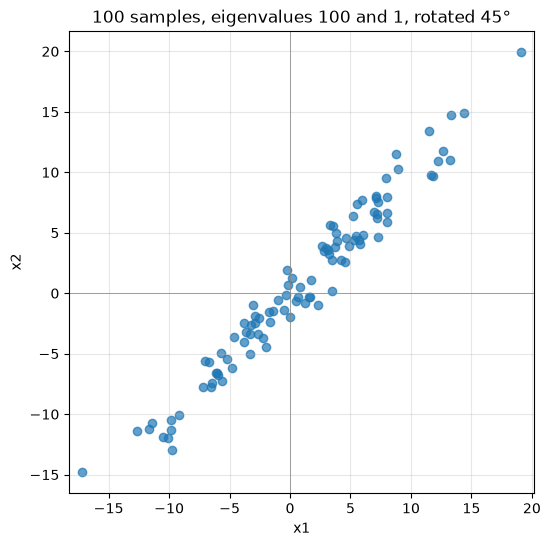

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(points[:, 0], points[:, 1], alpha=0.7)
plt.axhline(0, color="gray", lw=0.5)
plt.axvline(0, color="gray", lw=0.5)
plt.axis("equal")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("100 samples, eigenvalues 100 and 1, rotated 45°")
plt.grid(alpha=0.3)
plt.show()


In [4]:
print(points)
    

[[  3.81242815   4.96716395]
 [  2.80686034   3.46111178]
 [ 12.62793715  11.77358433]
 [ 13.21600905  10.99673801]
 [  6.93754075   6.69737091]
 [ -0.247436     1.89890095]
 [  4.51957377   2.61948744]
 [ -6.09092991  -6.61872285]
 [ -2.86720157  -1.87492321]
 [  1.19981868  -0.82917549]
 [ -0.5144329   -1.4044578 ]
 [ -6.44349906  -7.42725796]
 [  3.01004014   3.74365437]
 [  3.47849125   0.14310257]
 [  2.61780155   3.88110772]
 [  3.33327369   5.67152079]
 [ -5.58446553  -7.28130081]
 [  0.7835276    0.48604006]
 [-11.37229873 -10.70605641]
 [-10.46445001 -11.86079956]
 [-17.18826155 -14.77702902]
 [ -3.04502055  -0.97271672]
 [ -1.72336722  -1.57752461]
 [  5.76303236   4.05403419]
 [ -3.65498103  -3.231491  ]
 [-12.68928529 -11.36290859]
 [  5.96813531   7.6869355 ]
 [  2.28686661  -0.97908354]
 [  7.1103199    8.00470302]
 [ 11.45694309  13.40439648]
 [ -5.23052791  -5.43880962]
 [ -7.20196688  -7.73444761]
 [  3.15419306   3.60836478]
 [  1.60398476  -0.31815906]
 [  0.12255926

In [ ]:
points[99]= [99, -35]

def diff_cauchy(points): 
    return (points[:,0] - points[:,1])
diff_lsm(points)

array([-1.15473579e+00, -6.54251448e-01,  8.54352823e-01,  2.21927103e+00,
        2.40169833e-01, -2.14633694e+00,  1.90008633e+00,  5.27792946e-01,
       -9.92278361e-01,  2.02899417e+00,  8.90024897e-01,  9.83758907e-01,
       -7.33614236e-01,  3.33538868e+00, -1.26330617e+00, -2.33824710e+00,
        1.69683528e+00,  2.97487547e-01, -6.66242315e-01,  1.39634955e+00,
       -2.41123253e+00, -2.07230383e+00, -1.45842607e-01,  1.70899818e+00,
       -4.23490032e-01, -1.32637671e+00, -1.71880019e+00,  3.26595016e+00,
       -8.94383120e-01, -1.94745339e+00,  2.08281707e-01,  5.32480734e-01,
       -4.54171715e-01,  1.92214382e+00, -1.14424596e+00,  2.14085781e+00,
       -1.45074987e+00,  2.59942211e+00, -1.00013966e+00,  1.18438211e+00,
       -9.20342478e-01,  1.95578625e+00,  1.40870252e+00, -1.16368225e+00,
       -4.53871985e-01, -7.77961859e-02,  9.07201393e-01,  5.76704123e-01,
        1.73813609e+00,  8.45885768e-01,  9.04277265e-02,  1.93056745e+00,
       -7.84453218e-01, -

In [6]:
def lsm(array):
    return (1/2)*np.sum(array**2)

lsm(diff_lsm(points))

np.float64(9074.495342260929)

In [7]:
def loss_cacuchy(array, c=1):
    return (c**2/2)*np.sum(np.log(1 + (array/c)**2))

loss_cacuchy(diff_lsm(points))

np.float64(46.93676490698877)

# Third Practice

### Authors: Guillem Calvo Gallardo 23500820 and Oscar Romero López 21865336

In [8]:
# Necessary libraries
import numpy as np
import math as math
import matplotlib.pyplot as plt

## 1. Introduction task

We define a set of samples form a lineal model with high noise.

In [9]:
m = [0.,0.]
angle = 45*math.pi/180
rot = np.array([[math.cos(angle), -math.sin(angle)], [math.sin(angle), math.cos(angle)]])
lamb = np.array([[100,0],[0,1]])
s = np.matmul(rot, np.matmul(lamb, rot.transpose()))
n = 100
points = np.random.multivariate_normal(m,s,n)

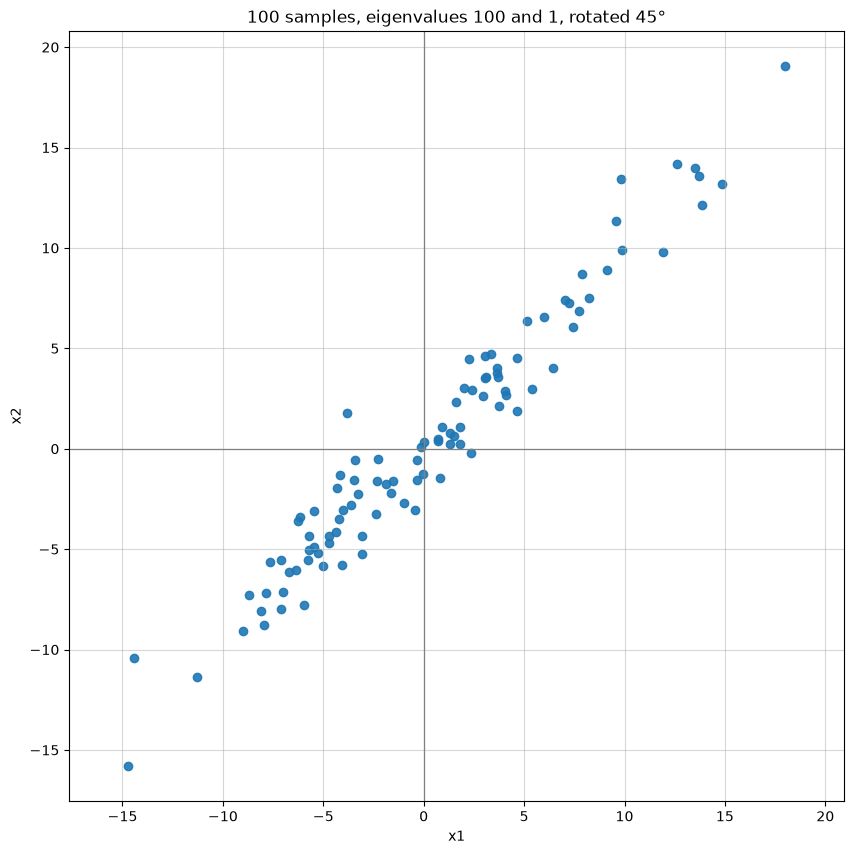

In [10]:
plt.figure(figsize=(10, 10))
plt.scatter(points[:, 0], points[:, 1], alpha=0.9)
plt.axhline(0, color="gray", lw=0.9)
plt.axvline(0, color="gray", lw=0.9)
plt.axis("equal")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title(f"{n} samples, eigenvalues {lamb[0,0]} and {lamb[1,1]}, rotated {int(angle*180/math.pi)}°")
plt.grid(alpha=0.5)
plt.show()


We will now try to find the linear model that fits best the set of points we defined.

Our model will be $w_{1}x + w_{0}$. The goal is to find the parameters $w_{1}$ and $w_{0}$ that minmize a function that might as well be the `Least Squares` function and then use any type of _descent method_ that helps us minimize the function.

#### Loss function model

The loss function model, applied to our case, consists in minimizing $Q$ given a set of points $\{(x_{i},y_{i})\}_{i=1}^{m}$, where $Q$ is the defined as:

$$
Q = \frac{1}{2} \sum_{i=1}^{m}(\hat{y}_{i}-y_{i})^{2}
$$

With $\hat{y}_{i} = f_lsm(x_{i})$, the value we expect from our model.

In other words, we want to minimize:

$$
Q = \frac{1}{2} \sum_{i=1}^{m}(w_{1}x_{i} + w_{0} - y_{i})^{2}
$$

To do so, we will use the tools from sessions 1 and 2. We consider $Q(w) = Q(w_{0}, w_{1})$ the function to minimize.

As we have done repeatedly in the past, we will calculate the gradient, skipping the calculations for the sake of simplicity and _cleanness_.

$$
\nabla Q =
\begin{pmatrix}
\dfrac{\partial Q}{\partial w_0} \\[2ex]
\dfrac{\partial Q}{\partial w_1}
\end{pmatrix}
=
\begin{pmatrix}
\displaystyle\sum_{i=1}^{m} (w_1 x_i + w_0 - y_i) \\[2ex]
\displaystyle\sum_{i=1}^{m} (w_1 x_i + w_0 - y_i)\,x_i
\end{pmatrix}
$$


### 1.1 Implement the Least Squares method

We will use backtracking to minimze $Q(w)$. We will be reusing the code from Session 2.

In [11]:
def LSM(array, w0, w1):
    return (1/2)*np.sum((w1 * array[:, 0] + w0 - array[:, 1])**2)

def LSM_grad(array, w0, w1):
    part_comu = w1 * array[:, 0] + w0 - array[:, 1]
    grad_w0 = np.sum(part_comu)
    grad_w1 = np.sum(part_comu * array[:, 0])
    return np.array([grad_w0, grad_w1])

# I made alpha really small in order to show how the model improves itself
def grad_desc_backtracking(f_lsm, grad_f_lsm, x0, x1, alpha0=0.001, tol=1e-5, max_iter=10000, alpha_min=1e-5):
    x = np.array([x0, x1])
    path = [x]
    alphas = []
    n_halvings = 0
    alpha = alpha0
    for k in range(max_iter):
        grad = grad_f_lsm(x)
        if np.linalg.norm(grad) < tol:
            break
        while f_lsm(x - alpha * grad) >= f_lsm(x) and alpha > alpha_min:
            alpha = alpha / 2
            n_halvings += 1
        x = x - alpha * grad
        path.append(x)
        alphas.append(alpha)
    return np.array(path), np.array(alphas), n_halvings

Model: w_0 = 0.1511, w_1 = 0.9480
This represents a 43.47º angle
562 iterations
2 halvings
LSM = 109.6946


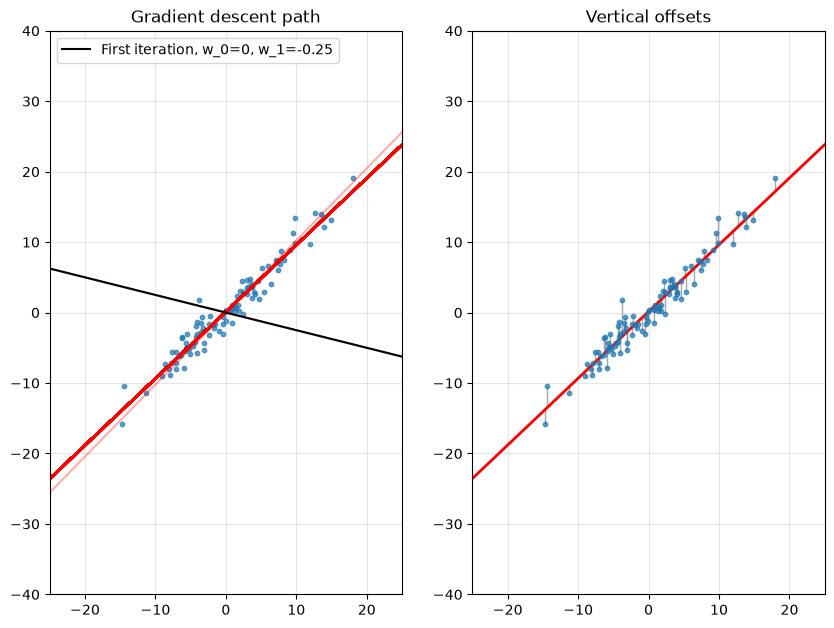

In [ ]:
def f_lsm(w):
    return LSM(points, w[0], w[1])

def grad_f_lsm(w):
    return LSM_grad(points, w[0], w[1])

path, alphas, n_halvings = grad_desc_backtracking(f_lsm, grad_f_lsm, 0, -0.25)
angle = np.degrees(np.arctan(path[-1][1]))
print(f"Model: w_0 = {path[-1][0]:.4f}, w_1 = {path[-1][1]:.4f}\nThis represents a {angle:.2f}º angle\n{len(path)} iterations\n{n_halvings} halvings\nLSM = {f_lsm(path[-1]):.4f}")

results_clean = {"w0": path[-1][0], "w1": path[-1][1], "angle": angle, "iters": len(path), "Q": f_lsm(path[-1])}

w0_opt, w1_opt = path[-1]
xs, ys = points[:, 0], points[:, 1]
y_hat = w0_opt + w1_opt * xs
residuals = ys - y_hat

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
#Plot 1
axs[0].scatter(xs, ys, alpha=0.7, s=10)
for k in range(len(path)):
    w0, w1 = path[k]
    axs[0].axline((0, w0), slope=w1, color="red", alpha=0.32 + 0.04 * k / (len(path) - 1))
axs[0].axline((0,path[0][0]), slope=path[0][1], color="black", label="First iteration, w_0=0, w_1=-0.25")
axs[0].legend(loc="upper left")
axs[0].set_title("Gradient descent path")

#Plot 2
axs[1].vlines(xs, y_hat, ys, color="gray", lw=1, alpha=0.7)
axs[1].scatter(xs, ys, alpha=0.7, s=10, zorder=3)
axs[1].axline((0, w0_opt), slope=w1_opt, color="red", lw=2)
axs[1].set_title("Vertical offsets")

for ax in axs:
    ax.set_xlim(-25, 25)
    ax.set_ylim(-40, 40)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
plt.show()

### 1.2 Outliers influence

In order to show the sensitiviy of our model to outliers we will edit one point of our dataset. This point will now be found at $\left[-40,20\right]$. Then we will compare both models and check the difference when just one point is an outlier.

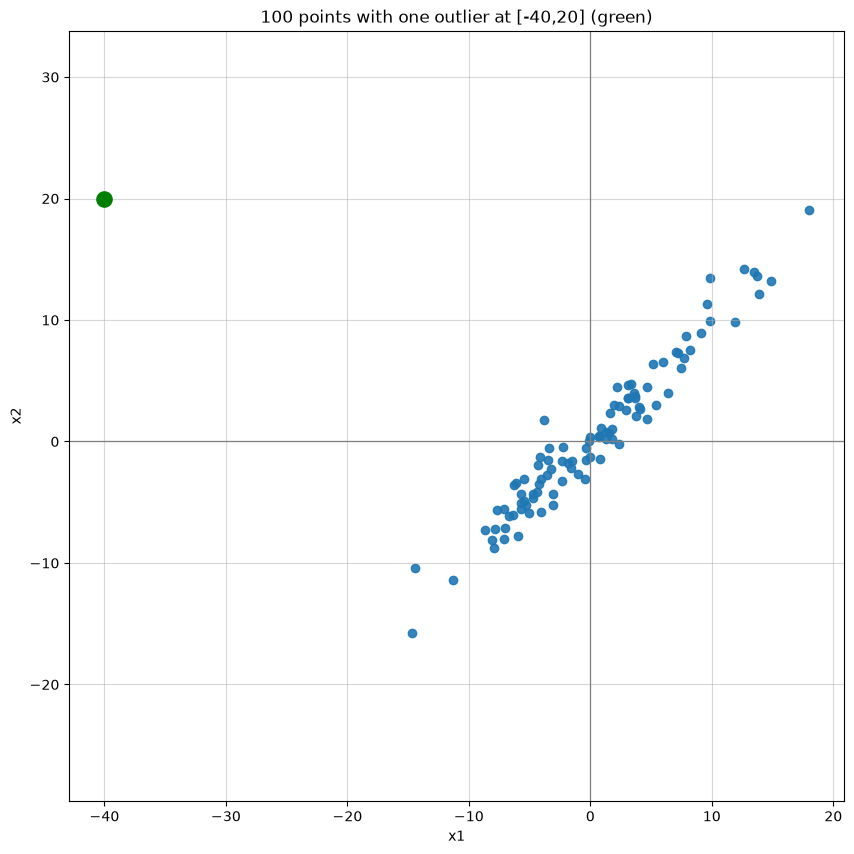

In [13]:
points_one_outlier = points
points_one_outlier[1] = [-40,20]

plt.figure(figsize=(10, 10))
plt.scatter(points_one_outlier[:, 0], points_one_outlier[:, 1], alpha=0.9)
plt.scatter(*points_one_outlier[1], color="green", s=120, zorder=3)
plt.axhline(0, color="gray", lw=0.9)
plt.axvline(0, color="gray", lw=0.9)
plt.axis("equal")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title(f"100 points with one outlier at [-40,20] (green)")
plt.grid(alpha=0.5)
plt.show()

Now we will repeat section 1.1 but with the edited dataset

Model: w_0 = 0.6965, w_1 = 0.5471
This represents a 28.69º angle
562 iterations
7 halvings
LSM = 1297.7945


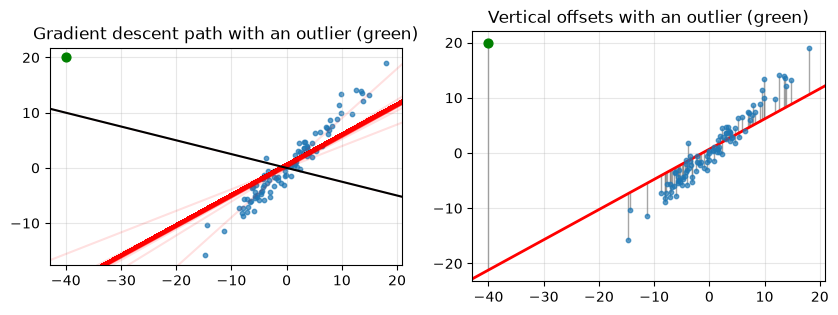

In [14]:
def f_lsm(w):
    return LSM(points_one_outlier, w[0], w[1])

def grad_f_lsm(w):
    return LSM_grad(points_one_outlier, w[0], w[1])

path_outlier, alphas_outleir, n_halvings_outlier = grad_desc_backtracking(f_lsm, grad_f_lsm, 0, -0.25)
angle_outlier = np.degrees(np.arctan(path_outlier[-1][1]))
print(f"Model: w_0 = {path_outlier[-1][0]:.4f}, w_1 = {path_outlier[-1][1]:.4f}\nThis represents a {angle_outlier:.2f}º angle\n{len(path)} iterations\n{n_halvings_outlier} halvings\nLSM = {f_lsm(path_outlier[-1]):.4f}")

results_out_outlier = {"w0": path_outlier[-1][0], "w1": path_outlier[-1][1], "angle": angle_outlier, "iters": len(path_outlier), "Q": f_lsm(path_outlier[-1])}

fig, axs = plt.subplots(1, 2, figsize=(10, 8))

#Plot 1
axs[0].scatter(xs, ys, alpha=0.7, s=10)
for k in range(len(path_outlier)):
    w0, w1 = path_outlier[k]
    axs[0].axline((0, w0), slope=w1, color="red", alpha=0.12 + 0.04 * k / (len(path_outlier) - 1))
axs[0].scatter(*points_one_outlier[1], color="green", s=40, zorder=3)
axs[0].set_title("Gradient descent path with an outlier (green)")

#Plot 2
w0_opt_outlier, w1_opt_outlier = path_outlier[-1]
xs_outlier, ys_outlier = points_one_outlier[:, 0], points_one_outlier[:, 1]
y_hat_outlier = w0_opt_outlier + w1_opt_outlier * xs
residuals_outlier = ys_outlier - y_hat_outlier

axs[1].vlines(xs_outlier, y_hat_outlier, ys_outlier, color="gray", lw=1, alpha=0.7)
axs[1].scatter(xs_outlier, ys_outlier, alpha=0.7, s=10, zorder=3)
axs[1].axline((0, w0_opt_outlier), slope=w1_opt_outlier, color="red", lw=2)
axs[0].axline((0,path[0][0]), slope=path[0][1], color="black", label="First iteration, w_0=0, w_1=-0.5")
axs[1].scatter(*points_one_outlier[1], color="green", s=40, zorder=3)
axs[1].set_title("Vertical offsets with an outlier (green)")

for ax in axs:
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
plt.show()

#### Conclusions

We compare the results obtained with and without the outlier:

In [15]:
Q = LSM(points, w0_opt, w1_opt)
Q_outlier = LSM(points_one_outlier, w0_opt_outlier, w1_opt_outlier)

print(f"{'':>10} | {'No outliers':>11} | {'With outliers':>13} | {'Difference %':>12}")
print("-" * 56)
print(f"{'w0':>10} | {w0_opt:>11.4f} | {w0_opt_outlier:>13.4f} | {100 * (w0_opt_outlier - w0_opt) / abs(w0_opt):>+11.2f}%")
print(f"{'w1':>10} | {w1_opt:>11.4f} | {w1_opt_outlier:>13.4f} | {100 * (w1_opt_outlier - w1_opt) / abs(w1_opt):>+11.2f}%")
print(f"{'Angle':>10} | {angle:>11.2f} | {angle_outlier:>13.2f} | {100 * (angle_outlier - angle) / abs(angle):>+11.2f}%")
print(f"{'Iterations':>10} | {len(path):>11} | {len(path_outlier):>13} | {100 * (len(path_outlier) - len(path)) / len(path):>+11.2f}%")
print(f"{'Q(w)':>10} | {Q:>11.2f} | {Q_outlier:>13.2f} | {100 * (Q_outlier - Q) / abs(Q):>+11.2f}%")


           | No outliers | With outliers | Difference %
--------------------------------------------------------
        w0 |      0.1511 |        0.6965 |     +360.85%
        w1 |      0.9480 |        0.5471 |      -42.28%
     Angle |       43.47 |         28.69 |      -34.01%
Iterations |         562 |          2823 |     +402.31%
      Q(w) |     1778.05 |       1297.79 |      -27.01%


# CONCLUSIONES POR HACER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER NIGGER 

- **Without the outlier** the model recovers the underlying structure of the data almost perfectly: the points were generated along the 45º direction (slope 1, intercept 0), and we obtain a slope very close to 1 and an intercept close to 0.
- **Changing a single point out of 100 (1% of the data) rotates the line by around 11º.** The new line no longer describes the bulk of the data well: it is pulled towards the outlier.
- **The reason is the squared loss.** The point $[-40, 20]$ is about 60 units away (vertically) from the original line, so its contribution to $Q$ alone is $\frac{1}{2}\cdot 60^2 \approx 1800$, much more than the contribution of all the other points together. Since the gradient of each term is proportional to its residual, the outlier dominates the descent direction, and the optimum is the line that sacrifices the fit of many "good" points to reduce that single large error.
- **The position of the outlier matters too.** It lies at $x = -40$, far from the center of the data, so it has a large lever effect on the slope $w_1$. The intercept $w_0$ shows a large relative difference only because its value is close to 0; in absolute terms it barely changes.
- **The optimization also becomes harder:** the method needs around three times as many iterations. The outlier widens the range of $x$ values, which makes $Q$ worse conditioned (a more elongated valley), so gradient descent progresses more slowly.

In conclusion, the Least Squares model is very sensitive to outliers: one bad sample is enough to noticeably change the fitted model. This motivates the use of **robust loss functions**, such as the Cauchy loss, which grow much more slowly for large residuals and therefore limit the influence of outliers.

In [ ]:
def cauchy(array, w0, w1, c=1):
    return ((c**2)/2)*np.sum(np.log(1+((w1 * array[:, 0] + w0 - array[:, 1])**2)/(c**2)))



In [18]:
def f_cauchy(w):
    return cauchy(points, w[0], w[1])

def grad_f_cauchy(w):
    return cauchy_grad(points, w[0], w[1])

path, alphas, n_halvings = grad_desc_backtracking(f_cauchy, grad_f_cauchy, 0, -0.25)
angle = np.degrees(np.arctan(path[-1][1]))
print(f"Model: w_0 = {path[-1][0]:.4f}, w_1 = {path[-1][1]:.4f}\nThis represents a {angle:.2f}º angle\n{len(path)} iterations\n{n_halvings} halvings\nLSM = {fcauchy(path[-1]):.4f}")

results_clean = {"w0": path[-1][0], "w1": path[-1][1], "angle": angle, "iters": len(path), "Q": f_cauchy(path[-1])}

w0_opt, w1_opt = path[-1]
xs, ys = points[:, 0], points[:, 1]
y_hat = w0_opt + w1_opt * xs
residuals = ys - y_hat

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
#Plot 1
axs[0].scatter(xs, ys, alpha=0.7, s=10)
for k in range(len(path)):
    w0, w1 = path[k]
    axs[0].axline((0, w0), slope=w1, color="red", alpha=0.32 + 0.04 * k / (len(path) - 1))
axs[0].axline((0,path[0][0]), slope=path[0][1], color="black", label="First iteration, w_0=0, w_1=-0.25")
axs[0].legend(loc="upper left")
axs[0].set_title("Gradient descent path")

#Plot 2
axs[1].vlines(xs, y_hat, ys, color="gray", lw=1, alpha=0.7)
axs[1].scatter(xs, ys, alpha=0.7, s=10, zorder=3)
axs[1].axline((0, w0_opt), slope=w1_opt, color="red", lw=2)
axs[1].set_title("Vertical offsets")

for ax in axs:
    ax.set_xlim(-25, 25)
    ax.set_ylim(-40, 40)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
plt.show()

NameError: name 'cauchy_grad' is not defined